# News Article Multiclass Classification

**Experiment 10 · Applied Machine Learning · UPES**  
Karan Chaubey and Himani Phartiyal · Faculty: Dr. Pavinder Yadav

**Aim.** Given an English news article, suggest the single BBC desk that would handle it. A sports story about broadcasting rights can contain business vocabulary. Can a model use the rest of the story to pick the right desk?

**Design.** Audit the suggested dataset, then compare two word-based classifiers and a majority-class baseline on a second public corpus. Choose the model by validation macro F1 and open the test set once. The last cell accepts a fresh article for the classroom demo.

Open this project folder in VS Code, select the Python kernel and use **Run All**. The two source files in `data/` allow the notebook to run offline.

## 1. Set up the experiment

The seed fixes the article split. Each candidate will use the same training and validation articles.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

DATA = Path("data")
SEED = 42

## 2. Audit the suggested Kaggle dataset

An article ID can be unique even when the words repeat. Count distinct bodies and complete texts within each label before choosing an evaluation design.

In [2]:
suggested = pd.read_csv(DATA / "news_classification_dataset.csv")
audit = suggested.groupby("Category").agg(
    rows=("Category", "size"),
    distinct_bodies=("Article_Text", "nunique"),
    distinct_full_texts=("Full_Text", "nunique")
)
print(f"{len(suggested):,} rows, {suggested.Article_Text.nunique()} unique bodies, "
      f"{suggested.Full_Text.nunique()} unique full texts")
display(audit)

30,000 rows, 8 unique bodies, 16 unique full texts


,rows,distinct_bodies,distinct_full_texts
Category,,,
Business,3814,1,2
Education,3756,1,2
Entertainment,3761,1,2
Health,3803,1,2
Politics,3756,1,2
Science,3686,1,2
Sports,3690,1,2
Technology,3734,1,2


## 3. Collect BBC articles

The BBC benchmark contains English news from 2004–2005. Each folder supplies the target label. Only the headline and body enter the classifier. The two corpora have different label sets and are analysed separately.

In [3]:
records = []
with ZipFile(DATA / "bbc-fulltext.zip") as archive:
    for filename in sorted(archive.namelist()):
        if re.fullmatch(r"bbc/[a-z]+/[0-9]+\.txt", filename):
            article = archive.read(filename).decode("latin-1").strip()
            headline, _, body = article.partition("\n")
            records.append((filename, filename.split("/")[1], headline, body.strip()))

raw = pd.DataFrame(records, columns=["file", "category", "headline", "body"])
print(f"{len(raw):,} articles across {raw.category.nunique()} desks")
display(raw.category.value_counts().rename("Original articles").to_frame())

2,225 articles across 5 desks


,Original articles
category,
sport,511
business,510
politics,417
tech,401
entertainment,386


## 4. Clean the text and remove repeat stories

Lowercase the text and replace punctuation with spaces. Keep the first article in filename order when a cleaned body or headline repeats. This reduces overlap between splits. Rewritten coverage with a different headline and body can still remain.

In [4]:
def clean_text(text):
    words = re.findall(r"[a-z]+", text.lower())
    return " ".join(words)

news = raw.copy()
news["headline_key"] = news.headline.map(clean_text)
news["body_key"] = news.body.map(clean_text)
news = news.loc[news.headline_key.ne("") & news.body_key.ne("")]
news = news.drop_duplicates("body_key").drop_duplicates("headline_key").copy()
news["text"] = news.headline_key + " " + news.body_key

counts = pd.concat([raw.category.value_counts(), news.category.value_counts()], axis=1)
counts.columns = ["Original", "Retained"]
print(f"Removed {len(raw) - len(news)} records; retained {len(news):,}.")
display(counts.sort_index())

Removed 165 records; retained 2,060.


,Original,Retained
category,,
business,510,498
entertainment,386,362
politics,417,388
sport,511,489
tech,401,323


## 5. Reserve validation and test articles

Create stratified 60/20/20 splits. Validation compares candidates, while test measures the selected model after refitting. Stratification preserves the approximate share of each desk.

In [5]:
development, test = train_test_split(
    news, test_size=0.20, stratify=news.category, random_state=SEED
)
train, validation = train_test_split(
    development, test_size=0.25, stratify=development.category, random_state=SEED
)
parts = {"Train": train, "Validation": validation, "Test": test}
split_counts = pd.DataFrame({name: part.category.value_counts()
                             for name, part in parts.items()}).sort_index()
split_counts.loc["Total"] = split_counts.sum()
display(split_counts)
assert news.headline_key.is_unique and news.body_key.is_unique

,Train,Validation,Test
category,,,
business,298,100,100
entertainment,218,72,72
politics,233,78,77
sport,293,98,98
tech,194,64,65
Total,1236,412,412


## 6. Turn words into features

TF-IDF gives a word more weight when it occurs frequently in an article and appears in fewer training documents. The vectorizer splits text into single words, skips English stop words and keeps terms found in at least two training articles. The example prints actual weights.

In [6]:
def vectorizer():
    return TfidfVectorizer(preprocessor=clean_text, stop_words="english", min_df=2)

features = vectorizer()
matrix = features.fit_transform(train.text)
example = "The team scored a goal in the final football match."
weights = features.transform([example]).toarray()[0]
print("Training matrix (articles, vocabulary):", matrix.shape)
print("Words with positive weights in the example:")
display(pd.Series(weights, index=features.get_feature_names_out())
        .loc[lambda values: values > 0].sort_values(ascending=False)
        .round(3).rename("TF-IDF").to_frame())

Training matrix (articles, vocabulary): (1236, 12245)
Words with positive weights in the example:


,TF-IDF
scored,0.500
goal,0.444
football,0.426
match,0.372
team,0.343
final,0.339


## 7. Train and compare models

Naive Bayes combines evidence from words that occur in each class. Logistic regression learns a separate set of word weights for each desk. The baseline always chooses the most common training class. Macro F1 gives every desk equal influence.

In [7]:
candidates = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic regression": LogisticRegression(max_iter=500, random_state=SEED)
}

def scores(actual, predicted):
    p, r, f, _ = precision_recall_fscore_support(
        actual, predicted, average="macro", zero_division=0
    )
    return {"Accuracy": accuracy_score(actual, predicted), "Macro precision": p,
            "Macro recall": r, "Macro F1": f}

rows = []
for name, classifier in candidates.items():
    model = make_pipeline(vectorizer(), clone(classifier))
    model.fit(train.text, train.category)
    predicted = model.predict(validation.text)
    rows.append({"Model": name, **scores(validation.category, predicted)})

comparison = pd.DataFrame(rows).set_index("Model")
winner = comparison["Macro F1"].idxmax()
display(comparison.round(4))
print("Selected on validation:", winner)

,Accuracy,Macro precision,Macro recall,Macro F1
Model,,,,
Majority baseline,0.2427,0.0485,0.2000,0.0781
Multinomial Naive Bayes,0.9587,0.9637,0.9521,0.9567
Logistic regression,0.9733,0.9763,0.9695,0.9725


Selected on validation: Logistic regression


## 8. Read the validation comparison

The common scale runs from zero to one. The table in the previous cell gives precise values for the two closely matched classifiers.

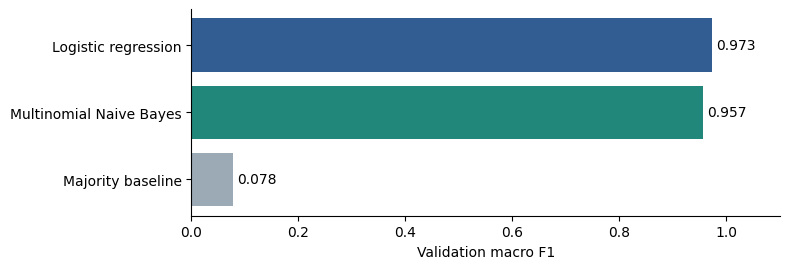

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(comparison.index, comparison["Macro F1"],
               color=["#9caab5", "#21877a", "#315d93"])
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set(xlim=(0, 1.10), xlabel="Validation macro F1")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 9. Test the selected model

Refit the winning pipeline on training and validation articles combined. Read the held-out test results overall and by desk. Support is the number of test articles belonging to a desk.

In [9]:
final_model = make_pipeline(vectorizer(), clone(candidates[winner]))
final_model.fit(development.text, development.category)
predicted = final_model.predict(test.text)
test_scores = scores(test.category, predicted)
correct = (test.category == predicted).sum()
print(f"{winner}: {correct} correct out of {len(test)} test articles")
display(pd.Series(test_scores).round(4).rename("Test score").to_frame())
print(classification_report(test.category, predicted, digits=3, zero_division=0))

Logistic regression: 404 correct out of 412 test articles


,Test score
Accuracy,0.9806
Macro precision,0.9799
Macro recall,0.9807
Macro F1,0.9802


               precision    recall  f1-score   support

     business      0.970     0.970     0.970       100
entertainment      1.000     0.972     0.986        72
     politics      0.974     0.987     0.981        77
        sport      1.000     0.990     0.995        98
         tech      0.955     0.985     0.970        65

     accuracy                          0.981       412
    macro avg      0.980     0.981     0.980       412
 weighted avg      0.981     0.981     0.981       412



## 10. Locate the mistakes

Rows show the actual desk. Columns show the predicted desk. A cell off the diagonal counts articles sent to the wrong desk.

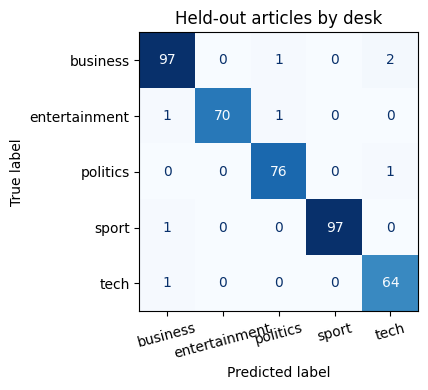

In [10]:
labels = sorted(news.category.unique())
cm = confusion_matrix(test.category, predicted, labels=labels)
fig, ax = plt.subplots(figsize=(6.5, 4))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=15
)
ax.set_title("Held-out articles by desk")
fig.tight_layout()
plt.show()

## 11. Explain one prediction

Inspect the strongest word signals for each desk and one held-out mistake. For logistic regression these are the largest coefficients. For Naive Bayes these are the highest log-probabilities within each class.

In [11]:
import numpy as np

vocab = final_model.steps[0][1].get_feature_names_out()
classifier = final_model.steps[-1][1]
weights = getattr(classifier, "coef_", None)
if weights is None:
    weights = classifier.feature_log_prob_
for label, row in zip(classifier.classes_, weights):
    print(f"{label:14} {', '.join(vocab[np.argsort(row)[-5:][::-1]])}")

review = test[["headline", "category"]].assign(predicted=predicted)
mistakes = review[review.category != review.predicted]
if len(mistakes):
    print("\nFirst test error")
    print(mistakes.iloc[0].to_string())

business       bn, bank, shares, firm, economy
entertainment  film, music, band, album, singer
politics       mr, labour, blair, party, election
sport          cup, match, win, rugby, coach
tech           technology, computer, online, games, mobile

First test error
headline     UK firms 'embracing e-commerce'
category                            politics
predicted                               tech


## 12. Try a new article

Edit the sentence and rerun this cell during the presentation. A blank input or an input with no known terms triggers a message asking for more text.

In [12]:
def predict_desk(article):
    vector = final_model.steps[0][1].transform([article])
    if vector.nnz == 0:
        return "Please add more detail using recognisable English words."
    return final_model.predict([article])[0]

new_article = "The striker scored twice as the football club reached the cup final."
print(new_article)
print("Suggested desk:", predict_desk(new_article))

The striker scored twice as the football club reached the cup final.
Suggested desk: sport


## Conclusion and future scope

Logistic regression led on validation macro F1 (0.9725), ahead of Naive Bayes (0.9567) and the majority baseline (0.0781). After refitting, it assigned 404 of 412 held-out stories to the correct desk. Test accuracy was 98.06% and macro F1 was 0.9802.

One politics story about UK firms adopting e-commerce went to the tech desk. The headline illustrates why a story can sound right for more than one desk.

The BBC articles come from one publisher in 2004–2005. Test performance applies to this cleaned sample. A useful next experiment would freeze this model and test it on newly labelled articles from several publishers. An editor could review mixed-topic stories before publication.

**Dataset sources**  
Suggested Kaggle dataset by mmumairkhattak: https://www.kaggle.com/datasets/mmumairkhattak/news-classification-dataset-2026-nlp-and-tc  
BBC corpus by Derek Greene and Pádraig Cunningham: https://github.com/derekgreene/bbc-datasets  
Greene & Cunningham, *Practical Solutions to the Problem of Diagonal Dominance in Kernel Document Clustering*, ICML 2006. BBC retains copyright in the articles. The corpus is available for non-commercial and research use.